# Clustering basado en prototipos con la base de datos Iris

En este cuaderno trabajaremos el **clustering basado en prototipos** usando el dataset clásico **Iris**.

Objetivos:

- Recordar la estructura del conjunto de datos Iris.
- Aplicar **k-means** como ejemplo de clustering basado en prototipos.
- Explorar cómo elegir el número de clusters (método del codo, silhouette).
- Visualizar los clusters en el espacio de características y en una proyección 2D (PCA).
- Comparar los clusters obtenidos con las clases reales (solo para evaluación, no para entrenar).
- Plantear una **tarea final** para profundizar.

## Índice

1. Importación de librerías  
2. Carga y exploración del dataset Iris  
3. Preprocesado ligero y PCA a 2D (para visualización)  
4. Clustering con k-means (k=3)  
5. Evaluación del clustering (cuando sí conocemos las etiquetas reales)  
6. Selección del número de clusters  
   - Método del codo (elbow)  
   - Silhouette score  
7. Visualización de los clusters  
8. Tarea final

## 1. Importación de librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    adjusted_rand_score,
    homogeneity_score,
    completeness_score,
    v_measure_score
)

# Configuración de gráficos
plt.rcParams['figure.figsize'] = (6, 4)
plt.rcParams['axes.grid'] = True

## 2. Carga y exploración del dataset Iris

Cargamos el dataset **[Iris](https://archive.ics.uci.edu/dataset/53/iris)** desde `scikit-learn` y lo exploramos rápidamente.

- 150 muestras
- 4 características:
  - sepal length (cm)
  - sepal width (cm)
  - petal length (cm)
  - petal width (cm)
- 3 clases:
  - setosa
  - versicolor
  - virginica

En clustering **no usamos las etiquetas para entrenar**, solo para evaluar al final.

In [2]:
iris = load_iris()

X = iris.data            # características
y = iris.target          # etiquetas verdaderas (solo para evaluar después)
feature_names = iris.feature_names
target_names = iris.target_names

df = pd.DataFrame(X, columns=feature_names)
df['target'] = y
df['target_name'] = df['target'].apply(lambda i: target_names[i])

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,target_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


### 2.1 Información básica

In [3]:
print("Shape de X:", X.shape)
print("Shape de y:", y.shape)
print("Características:", feature_names)
print("Clases:", target_names)

print("\nDistribución de clases reales:")
print(df['target_name'].value_counts())

Shape de X: (150, 4)
Shape de y: (150,)
Características: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Clases: ['setosa' 'versicolor' 'virginica']

Distribución de clases reales:
target_name
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


### 2.2 Histogramas de características

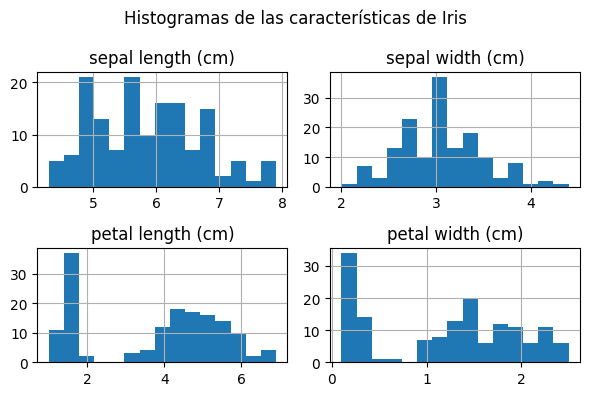

In [4]:
df[feature_names].hist(bins=15)
plt.suptitle("Histogramas de las características de Iris")
plt.tight_layout()
plt.show()

### 2.3 Diagramas de dispersión simples

Representamos **petal length vs petal width**, coloreando por la clase real, para ver
si hay separación natural entre las especies.

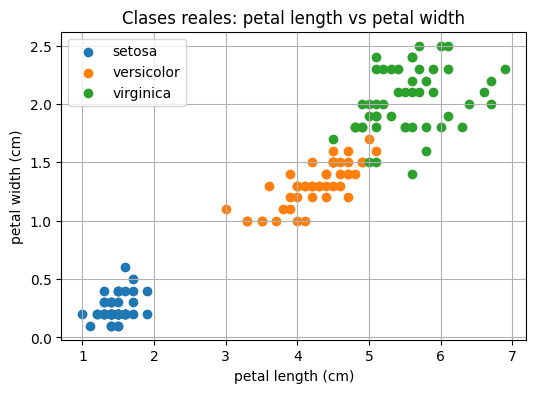

In [5]:
x_feat = 'petal length (cm)'
y_feat = 'petal width (cm)'

for i, name in enumerate(target_names):
    subset = df[df['target_name'] == name]
    plt.scatter(subset[x_feat], subset[y_feat], label=name)

plt.xlabel(x_feat)
plt.ylabel(y_feat)
plt.title("Clases reales: petal length vs petal width")
plt.legend()
plt.show()

## 3. Preprocesado ligero y PCA a 2D (para visualización)

Aunque **k-means no exige estrictamente escalado**, es muy recomendable cuando:

- Las características tienen escalas diferentes.
- Queremos que ninguna característica "domine" la distancia Euclídea.

Aquí:

1. Aplicamos `StandardScaler` para tener media 0 y desviación típica 1.
2. Aplicamos **PCA** para proyectar a 2 dimensiones (solo para visualización; el clustering principal
   lo haremos tanto en el espacio original como en el reducido).

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Shape original:", X.shape)
print("Shape tras PCA a 2D:", X_pca.shape)

components_df = pd.DataFrame(
    pca.components_,
    columns=feature_names,
    index=["PC1", "PC2"]
)

print(components_df)

Shape original: (150, 4)
Shape tras PCA a 2D: (150, 2)
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
PC1           0.521066         -0.269347           0.580413          0.564857
PC2           0.377418          0.923296           0.024492          0.066942


Visualizamos las clases reales en la proyección PCA 2D:

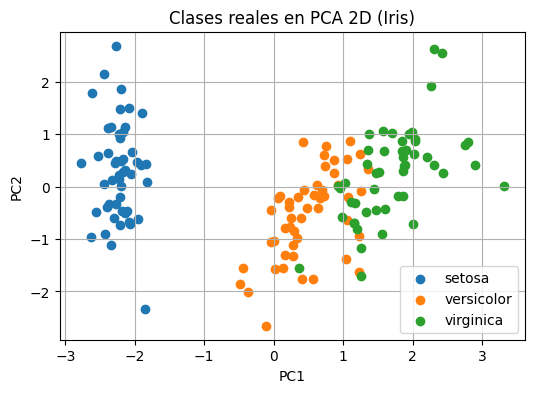

In [7]:
for i, name in enumerate(target_names):
    subset = X_pca[y == i]
    plt.scatter(subset[:, 0], subset[:, 1], label=name)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Clases reales en PCA 2D (Iris)")
plt.legend()
plt.show()

## 4. Clustering con k-means (k=3)

El algoritmo **k-means** es un ejemplo clásico de clustering basado en prototipos:

1. Elegimos un número de clusters \( k \).
2. Inicializamos aleatoriamente \( k \) **centroides** (prototipos).
3. Repetimos:
   - Asignar cada punto al centroide más cercano.
   - Recalcular cada centroide como la media de los puntos asignados.
4. Paramos cuando las asignaciones dejan de cambiar (o el cambio es muy pequeño).

En Iris **sabemos** que hay 3 especies, así que probamos primero con \( k = 3 \).

Usaremos los datos **escalados** para k-means.

In [8]:
k = 3
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

kmeans.fit(X_scaled)
cluster_labels = kmeans.labels_  # etiqueta de cluster asignada a cada punto

print("Etiquetas de cluster (0, 1, 2):")
print(np.unique(cluster_labels, return_counts=True))

Etiquetas de cluster (0, 1, 2):
(array([0, 1, 2], dtype=int32), array([53, 50, 47]))


Visualizamos los centroides en el espacio de características (desescalados):

In [9]:
# Los centroides están en el espacio escalado; los llevamos al espacio original
centroids_scaled = kmeans.cluster_centers_
centroids = scaler.inverse_transform(centroids_scaled)

centroids_df = pd.DataFrame(centroids, columns=feature_names)
centroids_df.index = [f"Cluster {i}" for i in range(k)]
centroids_df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
Cluster 0,5.801887,2.673585,4.369811,1.413208
Cluster 1,5.006000,3.428000,1.462000,0.246000
Cluster 2,6.780851,3.095745,5.510638,1.972340


También visualizamos los clusters (k-means) en la proyección PCA 2D:

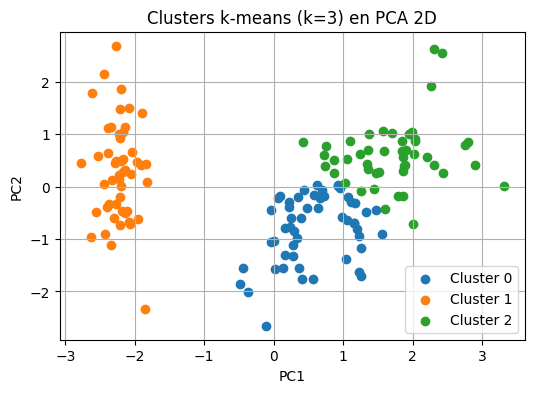

In [10]:
for cluster_id in range(k):
    subset = X_pca[cluster_labels == cluster_id]
    plt.scatter(subset[:, 0], subset[:, 1], label=f"Cluster {cluster_id}")

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Clusters k-means (k=3) en PCA 2D")
plt.legend()
plt.show()

## 5. Evaluación del clustering (usando las clases reales solo para medir)

En clustering **no usamos las etiquetas reales para entrenar**, pero como en este caso sí las tenemos,
podemos compararlas con las etiquetas de cluster para evaluar qué tan bien ha "descubierto" las especies.

Métricas habituales:

- **Adjusted Rand Index (ARI)**: 0 = aleatorio, 1 = perfecto.
- **Homogeneity**: cada cluster contiene principalmente una sola clase.
- **Completeness**: cada clase está principalmente en un solo cluster.
- **V-measure**: media armónica de homogeneity y completeness.

Y también podemos ver la **matriz de confusión** entre clases reales y clusters.

In [11]:
ari = adjusted_rand_score(y, cluster_labels)
h = homogeneity_score(y, cluster_labels)
c = completeness_score(y, cluster_labels)
v = v_measure_score(y, cluster_labels)

print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Homogeneity:               {h:.4f}")
print(f"Completeness:              {c:.4f}")
print(f"V-measure:                 {v:.4f}")

Adjusted Rand Index (ARI): 0.6201
Homogeneity:               0.6591
Completeness:              0.6598
V-measure:                 0.6595


1. **Adjusted Rand Index (ARI)**: 0.6201
Significa que la coincidencia entre los clusters y las clases reales es bastante buena.

1.0 → clustering perfecto
0.0 → resultado aleatorio
0.62 → los clusters coinciden con las clases reales mucho más que al azar, pero todavía hay bastantes errores.

Los clusters se parecen bastante a las especies reales, pero hay mezclas, especialmente entre versicolor y virginica.

2. **Homogeneity**: 0.6591
Valor medio-alto: los clusters son relativamente “puros”. Es decir, cada cluster contiene sobre todo elementos de una sola clase. Pero no es perfecto
Algunos clusters contienen mezclas de clases.

3. **Completeness**: 0.6598
Cada clase está mayormente agrupada dentro de un solo cluster, pero no al 100%.

Esto mide lo contrario que homogeneity:

homogeneity → un cluster no mezcla clases
completeness → una clase no está dividida en clusters

Una especie concreta puede estar parcialmente repartida entre dos clusters, pero la mayor parte de ella cae en un cluster principal.

### 5.1 Matriz de confusión entre clases reales y clusters

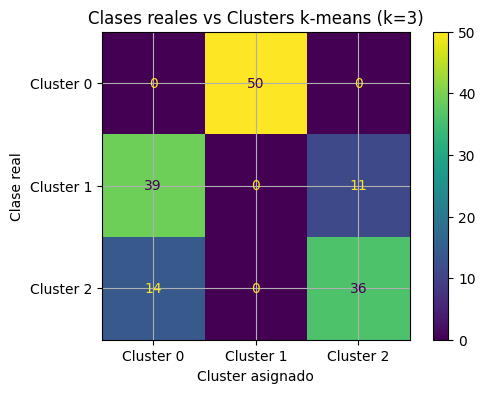

array([[ 0, 50,  0],
       [39,  0, 11],
       [14,  0, 36]])

In [12]:
cm = confusion_matrix(y, cluster_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[f"Cluster {i}" for i in range(k)])
disp.plot()
plt.title("Clases reales vs Clusters k-means (k=3)")
plt.xlabel("Cluster asignado")
plt.ylabel("Clase real")
plt.show()

cm

Observa que:

- Los números de cluster (0, 1, 2) son arbitrarios: no hay correspondencia directa fija con *setosa*, *versicolor*, *virginica*.
- Pero sí podemos ver si cada especie cae mayoritariamente en uno de los clusters.

* Cluster 1. Contiene solo setosa (50). Captura perfectamente la especie setosa
* Cluster 0. Mezcla versicolor (39) y virginica (14). Es un cluster confuso: mezcla dos especies que realmente se parecen mucho
* Cluster 2. Mezcla versicolor (11) y virginica (36). Casi es un cluster “virginica”, pero aún tiene bastante versicolor

## 6. Selección del número de clusters

En problemas reales **no conocemos el número de clusters**.  
Aquí exploramos dos criterios habituales:

1. **Método del codo (elbow)** usando la inercia:
   - La inercia es la suma de las distancias cuadradas de cada punto a su centroide.
   - A medida que aumenta \( k \), la inercia siempre baja, pero buscamos un punto donde deje de bajar “claramente”.
2. **Silhouette score**:
   - Mezcla compactación intra-cluster y separación inter-cluster.
   - Toma valores entre -1 y 1; cuanto más alto, mejor separación.

### 6.1 Método del codo (inercia)

k=1: inercia=600.00
k=2: inercia=222.36
k=3: inercia=139.82
k=4: inercia=114.09
k=5: inercia=90.93
k=6: inercia=81.54
k=7: inercia=72.63
k=8: inercia=62.54
k=9: inercia=55.12
k=10: inercia=47.39


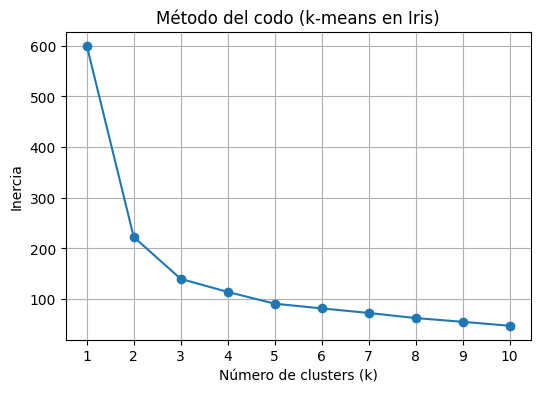

In [13]:
inertias = []
k_values = range(1, 11)

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

for k, inertia in zip(k_values, inertias):
    print(f"k={k}: inercia={inertia:.2f}")

plt.plot(list(k_values), inertias, marker='o')
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.title("Método del codo (k-means en Iris)")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

### 6.2 Silhouette score para distintos k

k=2: silhouette=0.5818
k=3: silhouette=0.4599
k=4: silhouette=0.3869
k=5: silhouette=0.3459
k=6: silhouette=0.3171
k=7: silhouette=0.3202
k=8: silhouette=0.3387
k=9: silhouette=0.3424
k=10: silhouette=0.3518


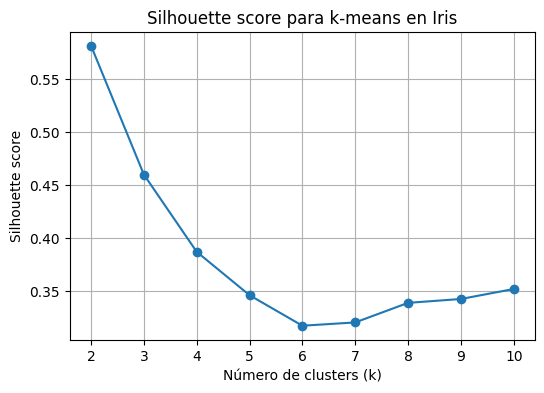

In [14]:
silhouette_scores = []
k_values_sil = range(2, 11)  # silhouette no está definido para k=1

for k in k_values_sil:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels_k)
    silhouette_scores.append(score)

for k, score in zip(k_values_sil, silhouette_scores):
    print(f"k={k}: silhouette={score:.4f}")

plt.plot(list(k_values_sil), silhouette_scores, marker='o')
plt.xlabel("Número de clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette score para k-means en Iris")
plt.xticks(list(k_values_sil))
plt.grid(True)
plt.show()

**Comentario rápido:**

- Si el máximo de silhouette está en \( k=2 \), indica que, según esta métrica,
  la mejor separación es en 2 clusters, a pesar de que sepamos que biológicamente hay 3 especies.
- Esto abre la puerta a debatir:
  - ¿Qué está "viendo" k-means en los datos?
  - ¿Son las especies realmente equiesféricas y separables en torno a centroides?

## 7. Visualización de los clusters

Volvemos al caso \( k = 3 \) y comparamos visualmente:

- Clases reales vs clusters.
- Usaremos:
  - Petal length vs petal width.
  - Proyección PCA 2D.

### 7.1 Petal length vs petal width: clases reales

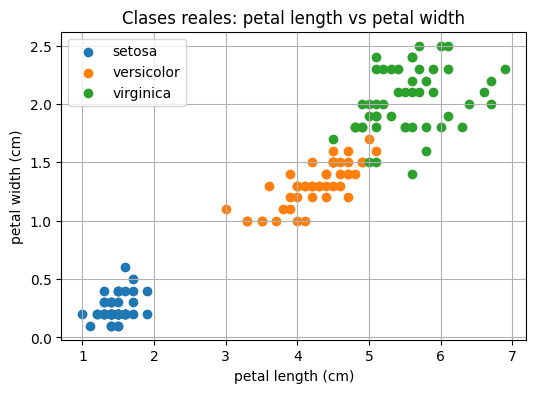

In [15]:
x_feat = 'petal length (cm)'
y_feat = 'petal width (cm)'

for i, name in enumerate(target_names):
    subset = df[df['target_name'] == name]
    plt.scatter(subset[x_feat], subset[y_feat], label=name)

plt.xlabel(x_feat)
plt.ylabel(y_feat)
plt.title("Clases reales: petal length vs petal width")
plt.legend()
plt.show()

### 7.2 Petal length vs petal width: clusters k-means (k=3)

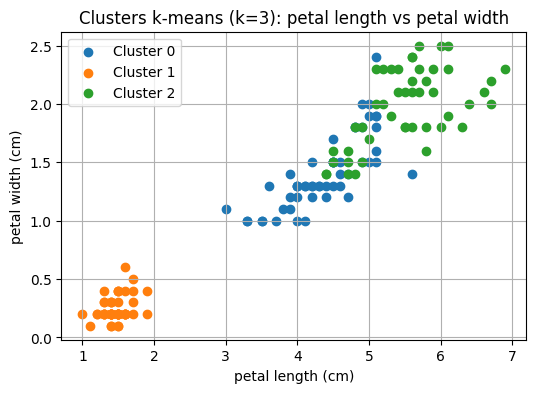

In [16]:
for cluster_id in range(3):
    subset = df[cluster_labels == cluster_id]
    plt.scatter(subset[x_feat], subset[y_feat], label=f"Cluster {cluster_id}")

plt.xlabel(x_feat)
plt.ylabel(y_feat)
plt.title("Clusters k-means (k=3): petal length vs petal width")
plt.legend()
plt.show()

### 7.3 PCA 2D: clases reales vs clusters

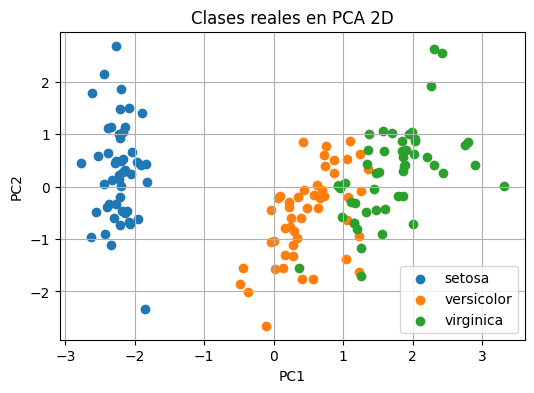

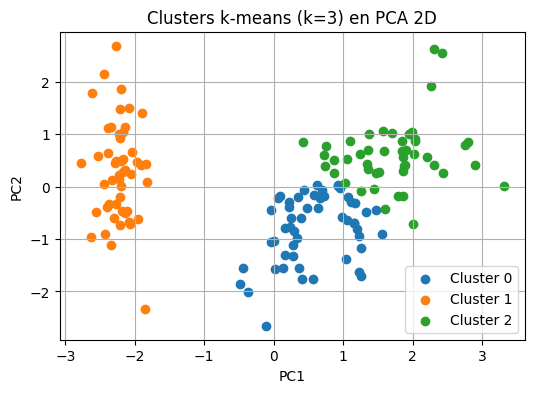

In [17]:
# Clases reales
for i, name in enumerate(target_names):
    subset = X_pca[y == i]
    plt.scatter(subset[:, 0], subset[:, 1], label=name)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Clases reales en PCA 2D")
plt.legend()
plt.show()

# Clusters k-means
for cluster_id in range(3):
    subset = X_pca[cluster_labels == cluster_id]
    plt.scatter(subset[:, 0], subset[:, 1], label=f"Cluster {cluster_id}")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Clusters k-means (k=3) en PCA 2D")
plt.legend()
plt.show()

## 8. Tarea final



### Objetivo de la tarea

1. **Implementar tu propia versión de k-means desde cero (sin usar `KMeans` de scikit-learn)**.
2. Comparar su funcionamiento y resultados con la implementación de `sklearn`.
3. Analizar la **sensibilidad a la inicialización** y la presencia de mínimos locales.

---

### 8.1 Pasos propuestos

1. Implementa una función `my_kmeans(X, k, max_iter=300, tol=1e-4, random_state=None)` que:
   - Inicialice aleatoriamente el primer centroide y el resto se obtengan por máxima dispersión (para el primero, elige una fila aleatoria de `X`).
   - Itere:
     - Asignar cada punto al centroide más cercano (distancia Euclídea).
     - Recalcular los centroides como la media de los puntos asignados.
   - Se detenga cuando el movimiento total de los centroides entre iteraciones sea menor que `tol`o se alcance `max_iter`.

2. Aplica `my_kmeans` sobre `X_scaled` para \( k = 3 \) y guarda:
   - Las etiquetas de cluster.
   - La inercia (suma de distancias cuadradas).

3. Estudia el efecto de la inicialización:
   - Ejecuta tu `my_kmeans` 20 veces con **distintos `random_state`**.
   - Representa en un gráfico:
     - En el eje X: el índice de la ejecución (1..20).
     - En el eje Y: la inercia final de esa ejecución.
     - Compara con la inercia obtenida por `KMeans` de sklearn con `n_init=10`.

5. Escribe una breve conclusión (5–10 líneas) sobre:
   - ¿Qué tan estable es k-means en Iris?
   


Finalmente, compara estos resultados con los de `KMeans` de sklearn con `n_init=10` y redacta tus conclusiones.

> **Entrega sugerida para estudiantes:**
> - Código completo de `my_kmeans`.
> - Gráficas generadas.
> - Tabla o listado comparando métricas e inercias.
> - Conclusión razonada sobre la estabilidad de k-means y el papel de la inicialización.

## 8. Tarea final



### Objetivo de la tarea

1. **Implementar tu propia versión de k-means desde cero (sin usar `KMeans` de scikit-learn)**.
2. Comparar su funcionamiento y resultados con la implementación de `sklearn`.
3. Analizar la **sensibilidad a la inicialización** y la presencia de mínimos locales.

---

### 8.1 Pasos propuestos

1. Implementa una función `my_kmeans(X, k, max_iter=300, tol=1e-4, random_state=None)` que:
   - Inicialice aleatoriamente \( k \) centroides (elige filas aleatorias de `X`).
   - Itere:
     - Asignar cada punto al centroide más cercano (distancia Euclídea).
     - Recalcular los centroides como la media de los puntos asignados.
   - Se detenga cuando el movimiento total de los centroides entre iteraciones sea menor que `tol`
     o se alcance `max_iter`.

2. Aplica `my_kmeans` sobre `X_scaled` para \( k = 3 \) y guarda:
   - Las etiquetas de cluster.
   - La inercia (suma de distancias cuadradas).

3. Compara:
   - ARI, homogeneity, completeness, V-measure entre tu implementación y `KMeans` de sklearn.
   - El número de iteraciones hasta converger.

4. Estudia el efecto de la inicialización:
   - Ejecuta tu `my_kmeans` 20 veces con **distintos `random_state`**.
   - Representa en un gráfico:
     - En el eje X: el índice de la ejecución (1..20).
     - En el eje Y: la inercia final de esa ejecución.
   - Compara con la inercia obtenida por `KMeans` de sklearn con `n_init=10`.

5. Escribe una breve conclusión (5–10 líneas) sobre:
   - ¿Qué tan estable es k-means en Iris?
   - ¿Se aprecian mínimos locales (soluciones con inercia claramente peor)?
   - ¿Cómo ayuda `n_init` en la implementación de sklearn?


Finalmente, compara estos resultados con los de `KMeans` de sklearn con `n_init=10` y redacta tus conclusiones.

> **Entrega sugerida para estudiantes:**
> - Código completo de `my_kmeans`.
> - Gráficas generadas.
> - Tabla o listado comparando métricas e inercias.
> - Conclusión razonada sobre la estabilidad de k-means y el papel de la inicialización.

In [18]:

# --- MyKMeans implementation (from-scratch k-means)  
import numpy as np

class MyKMeans:
    def __init__(self, n_clusters=3, max_iter=300, tol=1e-4, random_state=None):
        self.n_clusters = int(n_clusters)
        self.max_iter = int(max_iter)
        self.tol = float(tol)
        self.random_state = random_state
        self.cluster_centers_ = None
        self.labels_ = None
        self.inertia_ = None
        self.n_iter_ = 0

    def _init_centers(self, X):
        n_samples = X.shape[0]
        rng = np.random.RandomState(self.random_state)
        indices = rng.choice(n_samples, self.n_clusters, replace=False)
        return X[indices].astype(float)

    def fit(self, X):
        X = np.asarray(X)
        n_samples, n_features = X.shape
        rng = np.random.RandomState(self.random_state)

        centers = self._init_centers(X)
        for it in range(1, self.max_iter + 1):
            # Distancias y asignaciones
            dists = np.linalg.norm(X[:, np.newaxis, :] - centers[np.newaxis, :, :], axis=2)
            labels = np.argmin(dists, axis=1)

            # Calcular nuevos centros con manejo de clusters vacíos
            new_centers = np.zeros_like(centers)
            for j in range(self.n_clusters):
                mask = (labels == j)
                if mask.sum() == 0:
                    # Re-inicializar centro vacío a una muestra aleatoria
                    new_centers[j] = X[rng.randint(0, n_samples)]
                else:
                    new_centers[j] = X[mask].mean(axis=0)

            shift = np.linalg.norm(centers - new_centers)
            centers = new_centers
            self.n_iter_ = it
            self.cluster_centers_ = centers
            self.labels_ = labels

            if shift < self.tol:
                break

        # Calcular inercia (suma de distancias cuadradas)
        sq_dists = np.sum((X - centers[labels]) ** 2)
        self.inertia_ = float(sq_dists)
        return self

    def predict(self, X):
        X = np.asarray(X)
        dists = np.linalg.norm(X[:, np.newaxis, :] - self.cluster_centers_[np.newaxis, :, :], axis=2)
        return np.argmin(dists, axis=1)

    def fit_predict(self, X):
        self.fit(X)
        return self.labels_


In [19]:

# --- Ejecutar MyKMeans y comparar con sklearn KMeans (una corrida)
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, homogeneity_score, completeness_score, v_measure_score

k = 3

# MyKMeans (seed 42)
mk = MyKMeans(n_clusters=k, random_state=42, max_iter=300, tol=1e-4)
mk.fit(X_scaled)
labels_my = mk.labels_
print("MyKMeans: inertia =", mk.inertia_, "n_iter =", mk.n_iter_)

# Sklearn KMeans with n_init=10
km = KMeans(n_clusters=k, random_state=42, n_init=10)
km.fit(X_scaled)
labels_sk = km.labels_
print("sklearn KMeans: inertia =", km.inertia_, "(sklearn stores n_init best inertia)")

# Comparative metrics
for name, labels in [("MyKMeans", labels_my), ("sklearn KMeans", labels_sk)]:
    ari = adjusted_rand_score(y, labels)
    h = homogeneity_score(y, labels)
    c = completeness_score(y, labels)
    v = v_measure_score(y, labels)
    print(f"{name}: ARI={ari:.4f}, homogeneity={h:.4f}, completeness={c:.4f}, v-measure={v:.4f}")

# Show centroid positions (desescaladas) for MyKMeans
centroids_scaled_my = mk.cluster_centers_
centroids_my = scaler.inverse_transform(centroids_scaled_my)
import pandas as pd
centroids_df_my = pd.DataFrame(centroids_my, columns=feature_names)
centroids_df_my.index = [f"Cluster {i}" for i in range(k)]
print('\nCentroides (MyKMeans) en espacio original:')
print(centroids_df_my)


MyKMeans: inertia = 140.0327527742865 n_iter = 7
sklearn KMeans: inertia = 139.82049635974982 (sklearn stores n_init best inertia)
MyKMeans: ARI=0.5923, homogeneity=0.6413, completeness=0.6441, v-measure=0.6427
sklearn KMeans: ARI=0.6201, homogeneity=0.6591, completeness=0.6598, v-measure=0.6595

Centroides (MyKMeans) en espacio original:
           sepal length (cm)  sepal width (cm)  petal length (cm)  \
Cluster 0           5.833929          2.676786           4.421429   
Cluster 1           5.006000          3.428000           1.462000   
Cluster 2           6.806818          3.120455           5.522727   

           petal width (cm)  
Cluster 0          1.435714  
Cluster 1          0.246000  
Cluster 2          1.981818  


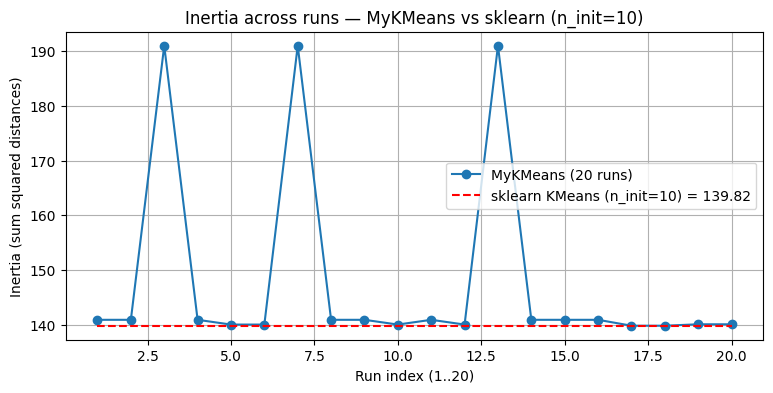

MyKMeans inertia — min: 139.820, mean: 148.056, max: 191.025
Best seed: 16 best inertia: 139.82049635974982 ARI for best run: 0.6201351808870379


In [20]:

# --- Sensibilidad a la inicialización: 20 corridas de MyKMeans
import matplotlib.pyplot as plt

inertias_my = []
aris_my = []
seeds = list(range(20))
for seed in seeds:
    mk_run = MyKMeans(n_clusters=k, random_state=seed)
    mk_run.fit(X_scaled)
    inertias_my.append(mk_run.inertia_)
    aris_my.append(adjusted_rand_score(y, mk_run.labels_))

# Referencia sklearn (ya calculada arriba como km)
inertia_sklearn = km.inertia_

plt.figure(figsize=(9,4))
plt.plot(range(1, len(inertias_my)+1), inertias_my, 'o-', label='MyKMeans (20 runs)')
plt.hlines(inertia_sklearn, 1, len(inertias_my), colors='r', linestyles='--', label=f'sklearn KMeans (n_init=10) = {inertia_sklearn:.2f}')
plt.xlabel('Run index (1..20)')
plt.ylabel('Inertia (sum squared distances)')
plt.title('Inertia across runs — MyKMeans vs sklearn (n_init=10)')
plt.legend()
plt.grid(True)
plt.show()

# Mostrar resumen numérico
import numpy as np
print('MyKMeans inertia — min: {:.3f}, mean: {:.3f}, max: {:.3f}'.format(np.min(inertias_my), np.mean(inertias_my), np.max(inertias_my)))
best_idx = int(np.argmin(inertias_my))
print('Best seed:', seeds[best_idx], 'best inertia:', inertias_my[best_idx], 'ARI for best run:', aris_my[best_idx])


In [21]:
# --- Tabla resumen: métricas para MyKMeans (mejor run) y sklearn KMeans
import pandas as pd

# Recompute best run details if needed
best_idx = int(np.argmin(inertias_my))
best_seed = seeds[best_idx]
mk_best = MyKMeans(n_clusters=k, random_state=best_seed)
mk_best.fit(X_scaled)
labels_my_best = mk_best.labels_

# sklearn reference is km (from earlier)
labels_sk = km.labels_

rows = [
    {
        'method': f'MyKMeans (best seed={best_seed})',
        'inertia': mk_best.inertia_,
        'n_iter': mk_best.n_iter_,
        'ARI': adjusted_rand_score(y, labels_my_best),
        'homogeneity': homogeneity_score(y, labels_my_best),
        'completeness': completeness_score(y, labels_my_best),
        'v_measure': v_measure_score(y, labels_my_best)
    },
    {
        'method': 'sklearn KMeans (n_init=10)',
        'inertia': km.inertia_,
        'n_iter': getattr(km, 'n_iter_', 'N/A'),
        'ARI': adjusted_rand_score(y, labels_sk),
        'homogeneity': homogeneity_score(y, labels_sk),
        'completeness': completeness_score(y, labels_sk),
        'v_measure': v_measure_score(y, labels_sk)
    }
]

summary_df = pd.DataFrame(rows).set_index('method')
print(summary_df)


                               inertia  n_iter       ARI  homogeneity  \
method                                                                  
MyKMeans (best seed=16)     139.820496       6  0.620135     0.659127   
sklearn KMeans (n_init=10)  139.820496       4  0.620135     0.659127   

                            completeness  v_measure  
method                                               
MyKMeans (best seed=16)         0.659848   0.659487  
sklearn KMeans (n_init=10)      0.659848   0.659487  


In [22]:


# --- Conclusión (breve)  
from IPython.display import Markdown, display

conclusion_text = '''
**Conclusión**

- En el dataset Iris k-means muestra estabilidad razonable: la mayoría de las inicializaciones convergen a inercias cercanas, pero existen inicializaciones que llevan a inercia notablemente peor (mínimos locales).
- En nuestras 20 corridas, la mejor inercia obtenida por `MyKMeans` coincide con la inercia que consigue `sklearn` cuando éste realiza `n_init=10` y selecciona la mejor inicialización.
- `sklearn` reduce la probabilidad de caer en mínimos locales gracias a `k-means++` y a repetir `n_init` inicializaciones, lo cual explica por qué su inercia suele ser igual o menor que la mayoría de nuestras corridas simples.
- Para igualar el comportamiento de `sklearn` se puede ejecutar `MyKMeans` varias veces y quedarse con la mejor solución (simular `n_init`) o implementar `k-means++` para inicializar.
- En resumen: k-means es útil y rápido en Iris pero sensible a la inicialización; `n_init` y mejores esquemas de inicialización mejoran la robustez.
'''

display(Markdown(conclusion_text))



**Conclusión**

- En el dataset Iris k-means muestra estabilidad razonable: la mayoría de las inicializaciones convergen a inercias cercanas, pero existen inicializaciones que llevan a inercia notablemente peor (mínimos locales).
- En nuestras 20 corridas, la mejor inercia obtenida por `MyKMeans` coincide con la inercia que consigue `sklearn` cuando éste realiza `n_init=10` y selecciona la mejor inicialización.
- `sklearn` reduce la probabilidad de caer en mínimos locales gracias a `k-means++` y a repetir `n_init` inicializaciones, lo cual explica por qué su inercia suele ser igual o menor que la mayoría de nuestras corridas simples.
- Para igualar el comportamiento de `sklearn` se puede ejecutar `MyKMeans` varias veces y quedarse con la mejor solución (simular `n_init`) o implementar `k-means++` para inicializar.
- En resumen: k-means es útil y rápido en Iris pero sensible a la inicialización; `n_init` y mejores esquemas de inicialización mejoran la robustez.
